# Two-pulse 2D THz spectra from semiclassical LLG

This notebook calculates the nonlinear two-pulse response $M_{\rm NL}(\tau,t)=M_{AB}-M_A-M_B+M_0$ of the two-sublattice LLG model, then Fourier transforms the delay $\tau$ and detection time $t$. Both delayed THz pulses have the same $ac$-bisector polarization, following the magnon-conversion protocol.

In [2]:
%load_ext autoreload
%autoreload 2

import copy
import time as wall_time
import numpy as np
import matplotlib.pyplot as plt

from two_spin_dynamics.llg import run_llg
from two_spin_dynamics.pulses import d2gdt2_pulse, two_thz_pulses
from two_spin_dynamics.plotting import LEGEND_STYLES, PLOT_CONFIG, plot_field_components, plot_magnetization_dynamics
from two_spin_dynamics.spectral_analysis import fft2_spectrum
from two_spin_dynamics.spin_hamiltonian import canted_afm_ground_state

plt.rcParams.update(PLOT_CONFIG)

## Hamiltonian, pulse, and 2D sampling parameters

In [5]:
# ErFeO3 parameters
temperature = 300.0  # K
ham_params = {
    'Stot': 2.5, 
    'nn': 6, 
    'Jex': 4.6, 
    'Dvec': np.array([0.0, 0.1066, 0.0]),
    'Kvec': np.array([0.00905, 0.0, 0.9847 / (temperature + 62.38) + 0.00265]),
}
S1_eq, S2_eq, beta0 = canted_afm_ground_state(ham_params)

# YFeO3 parameters
# ham_params = {
#     'Stot': 2.5, 
#     'nn': 6, 
#     'Jex': 4.96, 
#     'Dvec': np.array([0.0, 0.107, 0.0]),
#     'Kvec': np.array([0.00288, 0.0, 0.0008]),
# }

# pulse parameters
alpha = 0.0
sigma, h_peak = 0.5, 0.15  # ps, T
tau = np.linspace(0.0, 20.0, 2**6)  # ps: 0.5 ps delay sampling, ~0.05 THz delay resolution

t_detect_min, t_detect_max = 0.0, 20.0
dt_output = 0.02  # ps
time = np.arange(-tau[-1] - 4*sigma, t_detect_max + tau[-1] + dt_output/2, dt_output)
detect_mask = (time >= t_detect_min - 1e-12) & (time <= t_detect_max + 1e-12)
t_detect = time[detect_mask]

# Both pulses are along the ac bisector; A arrives tau ps before B.
ac_direction = np.array([1.0, 0.0, 1.0]) / np.sqrt(2.0)

def make_pulses(delay, state_a='on', state_b='on'):
    return {
        'A': {'shape_params': {'t0': -delay, 'sigma': sigma, 'h_peak': h_peak},
              'polarization': ac_direction, 'state': state_a},
        'B': {'shape_params': {'t0': 0.0, 'sigma': sigma, 'h_peak': h_peak},
              'polarization': ac_direction, 'state': state_b},
    }

print(f'beta_0 = {np.degrees(beta0):.4f} deg')
print(f'detection grid: {t_detect[0]:.1f} to {t_detect[-1]:.1f} ps; dt = {t_detect[1]-t_detect[0]:.3f} ps')
print(f'delay grid: {tau[0]:.1f} to {tau[-1]:.1f} ps; d_tau = {tau[1]-tau[0]:.3f} ps')

beta_0 = 0.6637 deg
detection grid: -0.0 to 20.0 ps; dt = 0.020 ps
delay grid: 0.0 to 20.0 ps; d_tau = 0.317 ps


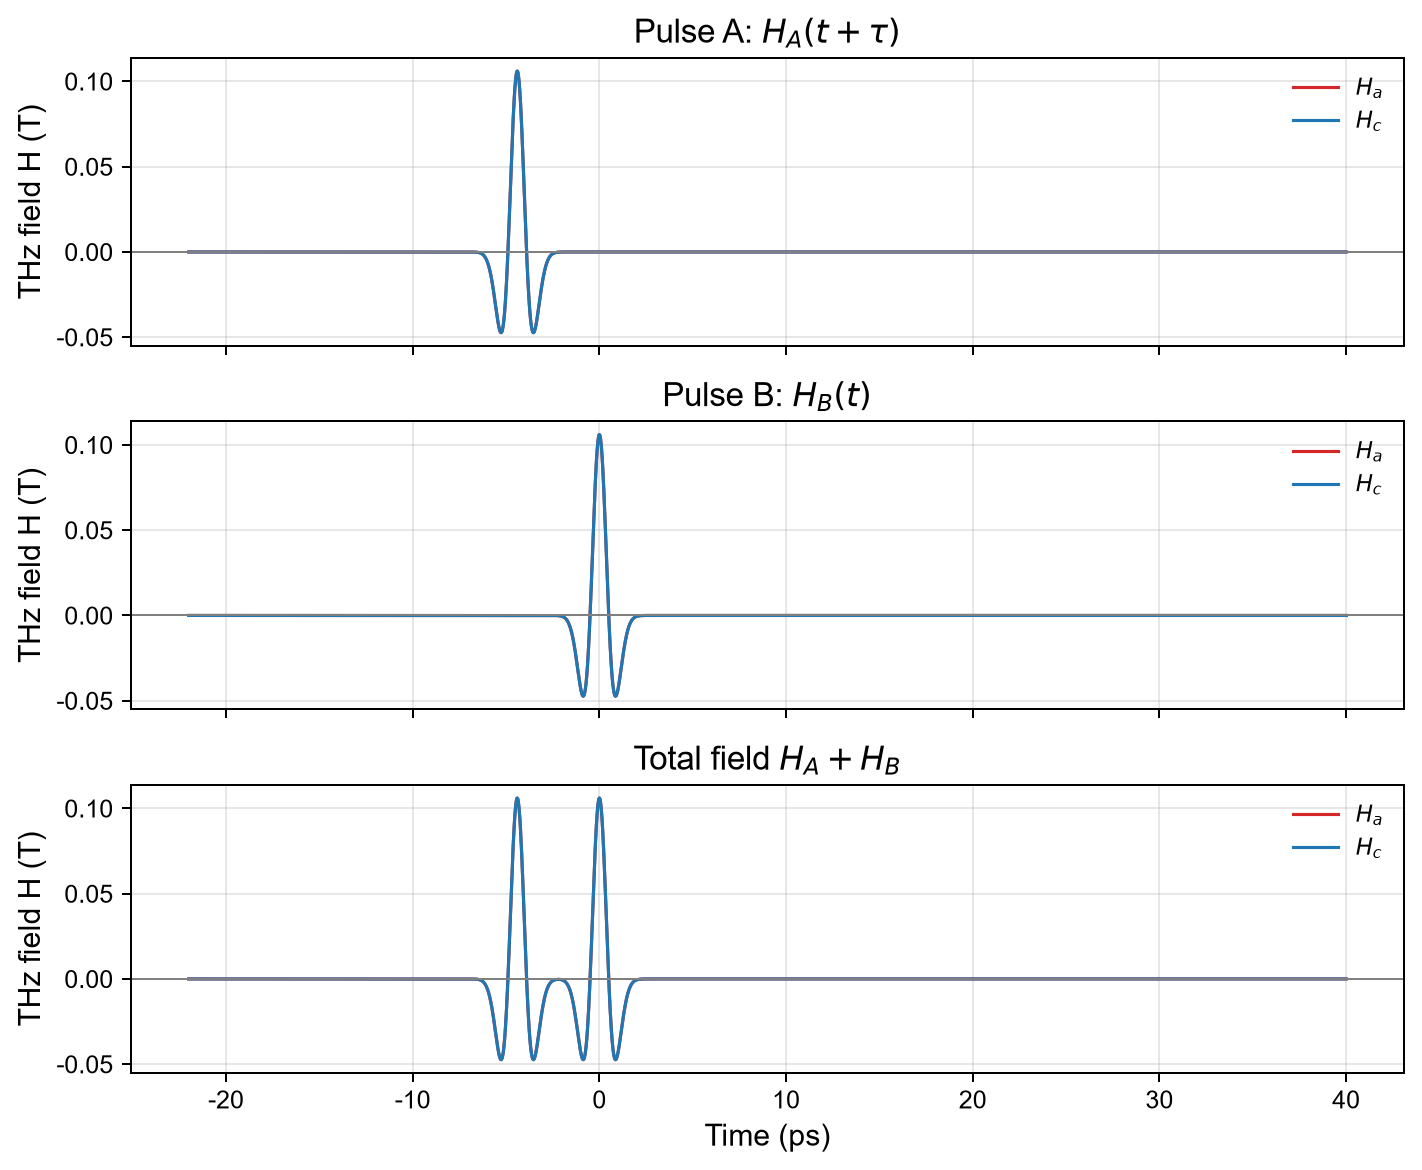

In [6]:
# Inspect the fields at a representative delay.
tau_example = 4.4
pulse_example = make_pulses(tau_example)
H_A = two_thz_pulses(time, make_pulses(tau_example, state_b='off'), d2gdt2_pulse)
H_B = two_thz_pulses(time, make_pulses(tau_example, state_a='off'), d2gdt2_pulse)
H_AB = two_thz_pulses(time, pulse_example, d2gdt2_pulse)

fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), dpi=180, sharex=True)
plot_field_components(axes[0], time, H_A, title=r'Pulse A: $H_A(t+\tau)$', xlabel=None)
plot_field_components(axes[1], time, H_B, title=r'Pulse B: $H_B(t)$', xlabel=None)
plot_field_components(axes[2], time, H_AB, title=r'Total field $H_A+H_B$')
fig.tight_layout()

## Cached reference simulations

$M_0$ and $M_B$ are delay-independent. Since the initial state is the exact ground state and A/B have identical shapes and polarization, $M_A(\tau,t)$ is obtained from the B-only result by interpolation at $t+\tau$; do not use this shortcut if adding a coherent initial perturbation or stochastic thermal noise.

In [7]:
solver_options = {'method': 'DOP853', 'rtol': 1e-9, 'atol': 1e-11, 'max_step': 0.02}

def simulate(pulse_parameters):
    return run_llg(time, S1_eq, S2_eq, ham_params, alpha, pulse_parameters, d2gdt2_pulse, **solver_options)['M']

t0 = wall_time.perf_counter()
M_0 = simulate(make_pulses(0.0, state_a='off', state_b='off'))
M_B = simulate(make_pulses(0.0, state_a='off', state_b='on'))
print(f'Cached M_0 and M_B in {wall_time.perf_counter()-t0:.2f} s')
print(f'Maximum pulse-off drift: {np.max(np.abs(M_0-M_0[0])):.3e}')

def shifted_A_only(delay):
    # A at -delay is the B-only response evaluated at t + delay. No np.roll: no wraparound.
    return np.column_stack([np.interp(time + delay, time, M_B[:, component]) for component in range(3)])

Cached M_0 and M_B in 9.11 s
Maximum pulse-off drift: 0.000e+00


## Delay scan and nonlinear response

Only the AB simulation is recomputed at each delay. The saved array has shape `(n_tau, n_t, 3)` and contains the nonlinear magnetization response.

In [8]:
M_nl = np.empty((tau.size, t_detect.size, 3))
scan_start = wall_time.perf_counter()

for index, delay in enumerate(tau):
    M_AB = simulate(make_pulses(delay, state_a='on', state_b='on'))
    M_A = shifted_A_only(delay)
    M_nl[index] = (M_AB - M_A - M_B + M_0)[detect_mask]
    if (index + 1) % 5 == 0 or index == 0:
        elapsed = wall_time.perf_counter() - scan_start
        estimate = elapsed / (index + 1) * tau.size
        print(f'{index+1:2d}/{tau.size}: tau = {delay:5.2f} ps; elapsed {elapsed:6.1f} s; estimated total {estimate/60:5.1f} min')

print(f'Completed delay scan in {(wall_time.perf_counter()-scan_start)/60:.2f} min')

 1/64: tau =  0.00 ps; elapsed    4.9 s; estimated total   5.2 min
 5/64: tau =  1.27 ps; elapsed   23.5 s; estimated total   5.0 min
10/64: tau =  2.86 ps; elapsed   47.8 s; estimated total   5.1 min
15/64: tau =  4.44 ps; elapsed   71.3 s; estimated total   5.1 min
20/64: tau =  6.03 ps; elapsed   94.2 s; estimated total   5.0 min
25/64: tau =  7.62 ps; elapsed  117.6 s; estimated total   5.0 min
30/64: tau =  9.21 ps; elapsed  141.1 s; estimated total   5.0 min
35/64: tau = 10.79 ps; elapsed  164.6 s; estimated total   5.0 min
40/64: tau = 12.38 ps; elapsed  187.2 s; estimated total   5.0 min
45/64: tau = 13.97 ps; elapsed  209.7 s; estimated total   5.0 min
50/64: tau = 15.56 ps; elapsed  232.2 s; estimated total   5.0 min
55/64: tau = 17.14 ps; elapsed  254.9 s; estimated total   4.9 min
60/64: tau = 18.73 ps; elapsed  277.7 s; estimated total   4.9 min
Completed delay scan in 4.93 min


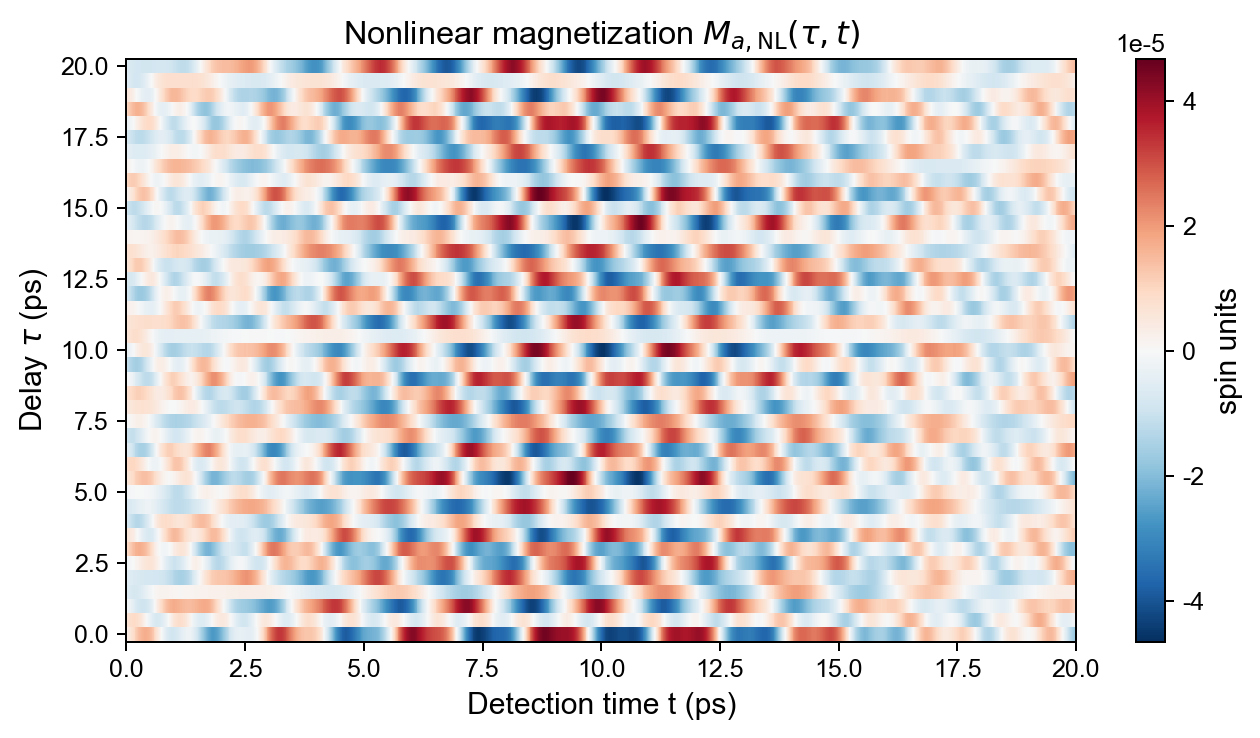

In [6]:
# The a component is the relevant emitted nonlinear magnetization channel for this geometry.
signal_a = M_nl[:, :, 0]

fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=180)
mesh = ax.pcolormesh(t_detect, tau, signal_a, shading='auto', cmap='RdBu_r')
ax.set(xlabel='Detection time t (ps)', ylabel=r'Delay $\tau$ (ps)', title=r'Nonlinear magnetization $M_{a,\rm NL}(\tau,t)$')
fig.colorbar(mesh, ax=ax, label='spin units')
fig.tight_layout()

## Two-dimensional Fourier transform

Delay-axis resolution: 0.0488 THz
Detection-axis resolution: 0.0500 THz


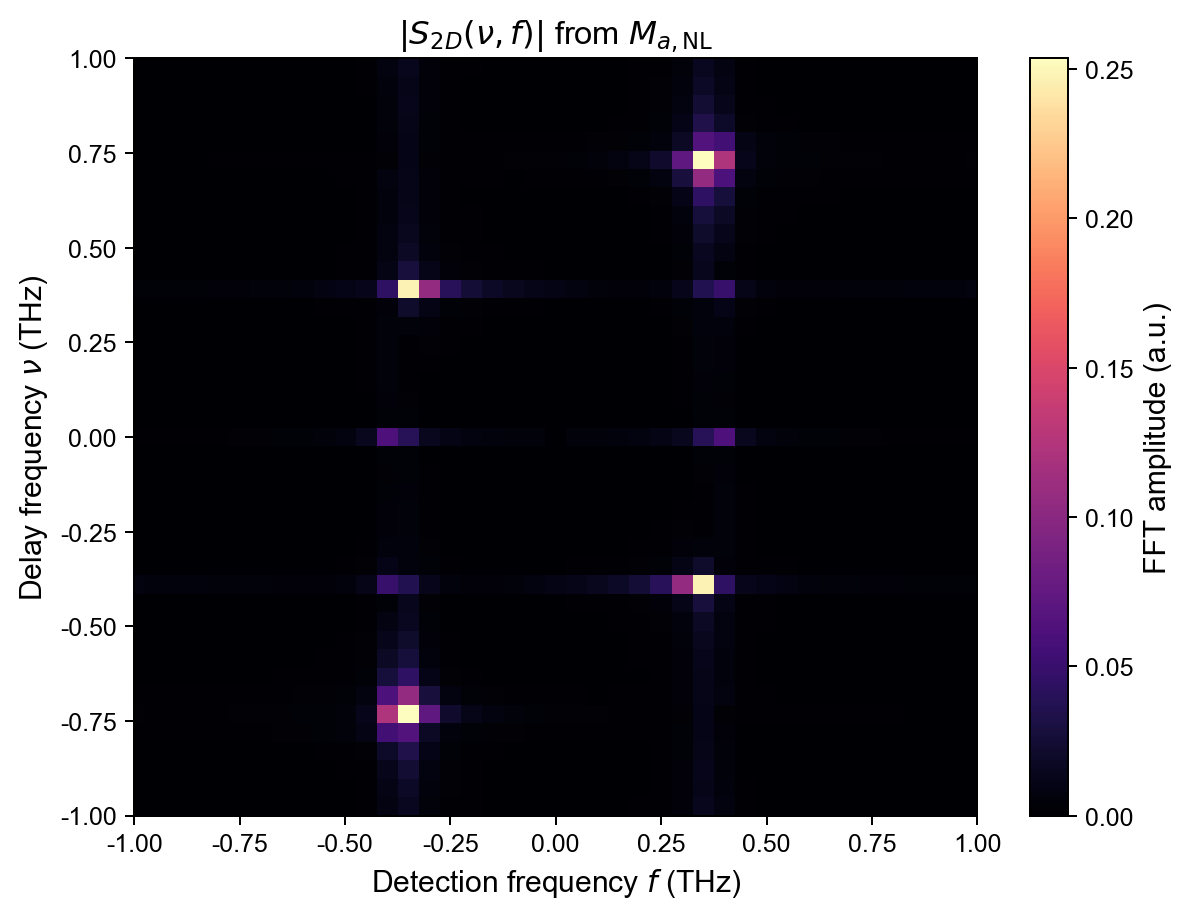

In [7]:
f_tau, f_t, spectrum_2d = fft2_spectrum(tau, t_detect, signal_a, remove_mean=True)
amplitude_2d = np.abs(spectrum_2d)

fig, ax = plt.subplots(figsize=(6.8, 5.2), dpi=180)
mesh = ax.pcolormesh(f_t, f_tau, amplitude_2d, shading='auto', cmap='magma')
ax.set(xlim=(-1.0, 1.0), ylim=(-1.0, 1.0), xlabel=r'Detection frequency $f$ (THz)', ylabel=r'Delay frequency $\nu$ (THz)', title=r'$|S_{2D}(\nu,f)|$ from $M_{a,\rm NL}$')
fig.colorbar(mesh, ax=ax, label='FFT amplitude (a.u.)')
fig.tight_layout()

print(f'Delay-axis resolution: {abs(f_tau[1]-f_tau[0]):.4f} THz')
print(f'Detection-axis resolution: {abs(f_t[1]-f_t[0]):.4f} THz')